# MATPLOTLIB MASTERY — NOTEBOOK 3
## Chapters 16–25: Horizontal Bars → Grouped Bars → Stacked Bars → Histograms → Histogram Bins → Box Plots → Violin Plots → Pie Charts → Area Plots → Fill Between

Continuing directly from Notebook 2. Run all cells in order.

### Progress Tracker (this notebook)
- [x] Chapter 16 — Horizontal Bar Charts
- [x] Chapter 17 — Grouped Bar Charts
- [x] Chapter 18 — Stacked Bar Charts
- [x] Chapter 19 — Histograms
- [x] Chapter 20 — Histogram Bin Selection
- [x] Chapter 21 — KDE Conceptual Comparison
- [x] Chapter 22 — Box Plots
- [x] Chapter 23 — Violin Plots
- [x] Chapter 24 — Pie Charts
- [x] Chapter 25 — Area Plots / Fill Between


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)


---
# CHAPTER 16 — HORIZONTAL BAR CHARTS

## 1. Concept
`ax.barh(y, width)` is the vertical-bar chart rotated 90°: categories run down the y-axis, magnitude runs along the x-axis. Everything from Chapter 15 (zero-baseline, sorting, value labels) applies identically, just transposed.

## 2. Why It Matters
Horizontal bars solve the single biggest weakness of vertical bars: **long category labels**. Rotated vertical-bar labels (45°/90°) are hard to read quickly; horizontal bars let labels run left-to-right, fully horizontal, no matter how long they are.

## 3–4. NumPy / Pandas Connection
`ax.barh(df["feature"], df["importance"])` is the standard call for feature importance plots — features often have long names ("avg_monthly_transaction_count") that would be unreadable as rotated vertical labels.

## 5. Industry Use Case
- **Feature importance** (the single most common use of `barh` in ML work — see Chapter 59).
- Long product/category names.
- Rankings/leaderboards.


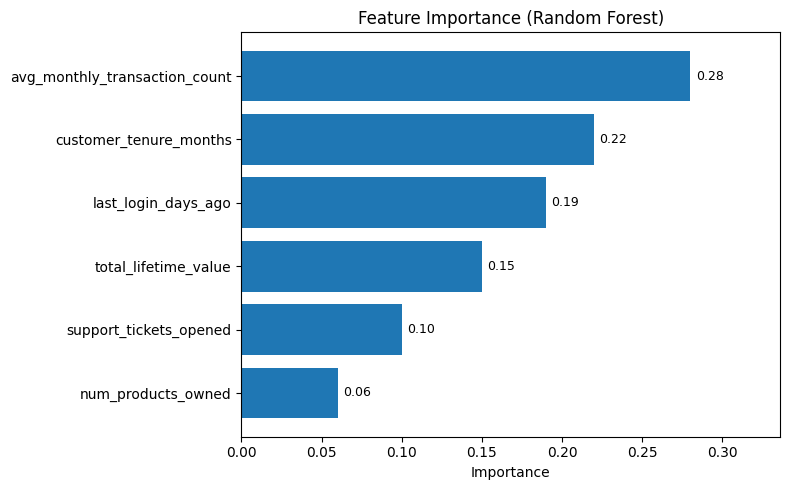

In [ ]:
features = [
    "avg_monthly_transaction_count", "customer_tenure_months", "last_login_days_ago",
    "total_lifetime_value", "support_tickets_opened", "num_products_owned",
]
importance = np.array([0.28, 0.22, 0.19, 0.15, 0.10, 0.06])

order = np.argsort(importance)   # ascending, so largest bar ends up at the TOP after barh
features_sorted = np.array(features)[order]
importance_sorted = importance[order]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(features_sorted, importance_sorted, color="tab:blue")

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.2f}", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)

ax.set_xlim(0, importance.max() * 1.2)
ax.set_title("Feature Importance (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


### Line-by-Line / Parameter Explanation
- `np.argsort(importance)` returns indices that would sort **ascending**. We deliberately sort ascending (not descending) because `barh` draws its *first* category at the *bottom* of the y-axis — so ascending order places the largest bar at the visual top, matching the natural "most important at top" reading convention.
- `bar.get_width()` / `bar.get_y()` / `bar.get_height()` — for horizontal bars, magnitude is encoded in **width**, not height; this is the key API difference from `ax.bar()`.
- `ax.set_xlim(0, ...)` — the zero-baseline rule (Chapter 10) now applies to the **x-axis** since that's the magnitude axis for `barh`.

### Internal Working
`ax.barh()` still returns a `BarContainer` of `Rectangle` Artists — identical Artist type to `ax.bar()`, just with width/height (and x/y) semantics swapped.

### Interpretation
`avg_monthly_transaction_count` and `customer_tenure_months` dominate this model's decisions — a plausible, business-explainable pattern (frequent, tenured customers behave predictably), which is exactly the kind of sanity check a feature-importance plot is meant to support before trusting a model.

### Common Mistakes
- Sorting descending and being surprised the largest bar appears at the **bottom** — remember `barh` plots top-to-bottom in the order given, so descending-sorted data actually puts the largest at the bottom unless you sort ascending (as done above) or explicitly invert the axis.
- Forgetting the x-axis (not y-axis) needs the zero-baseline check for `barh`.

### Debugging
If bars appear in an unexpected top-to-bottom order, print the sorted array right before plotting — this is almost always an ascending/descending sort direction mixup, not a Matplotlib bug.

### Best Practices
- Always sort feature-importance / ranking bars so the most important is at the top.
- Use `ax.invert_yaxis()` as an alternative to ascending-sort if you find descending-sort more intuitive to write — it flips the category order for you.

### Interview Insight
**Q: Why does `ax.barh()` need `np.argsort()` ascending, not descending, to put the biggest bar on top?**
A: `barh` renders categories bottom-to-top in the order the data is passed, so the *last* item in your array ends up visually at the *top*. Ascending sort puts the largest value last in the array, which lands it at the top of the chart.

### Mini Exercise
Recreate the plot using `ax.invert_yaxis()` on a **descending**-sorted array instead of ascending-sorting manually, and confirm you get the identical visual result.

### Quiz (Chapter 16)
1. Why is `barh` preferred over `bar` for long category names?
2. Which axis needs the zero-baseline check on a `barh` chart?
3. What's the ascending-vs-descending gotcha specific to `barh` ordering?


---
# CHAPTER 17 — GROUPED BAR CHARTS

## 1. Concept
A grouped ("clustered") bar chart places multiple bars side-by-side within each category, letting you compare **sub-groups** (e.g., multiple models, multiple years) against each other, category by category.

## 2. Why It Matters
The single most common ML reporting chart: "Precision / Recall / F1, side by side, for Model A vs Model B vs Model C." Grouped bars make both **within-category** (metric-to-metric) and **across-category** (model-to-model) comparisons possible on one chart.

## Building It With NumPy: The Offset Trick
Matplotlib has no built-in "grouped bar" function — you build it manually using NumPy-computed x-offsets per group. This is one of the most important small NumPy+Matplotlib patterns to memorize.


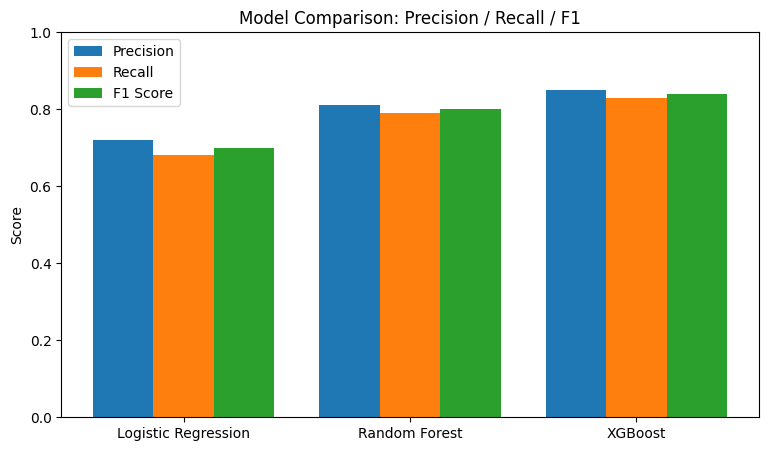

In [ ]:
models = ["Logistic Regression", "Random Forest", "XGBoost"]
metrics = {
    "Precision": [0.72, 0.81, 0.85],
    "Recall":    [0.68, 0.79, 0.83],
    "F1 Score":  [0.70, 0.80, 0.84],
}

x = np.arange(len(models))          # base positions: 0, 1, 2 (one per model)
n_metrics = len(metrics)
bar_width = 0.8 / n_metrics          # total width 0.8 split evenly across metrics

fig, ax = plt.subplots(figsize=(9, 5))

for i, (metric_name, values) in enumerate(metrics.items()):
    offset = (i - (n_metrics - 1) / 2) * bar_width   # centers the group around x
    ax.bar(x + offset, values, width=bar_width, label=metric_name)

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Model Comparison: Precision / Recall / F1")
ax.legend()
plt.show()


### Line-by-Line Explanation
- `x = np.arange(len(models))` — one base tick position per category (model): `[0, 1, 2]`.
- `bar_width = 0.8 / n_metrics` — Matplotlib's default bar `width` is `0.8` (leaving a small gap between category groups); dividing that total width evenly across however many sub-groups (metrics) you have keeps the whole cluster within that 0.8 footprint.
- `offset = (i - (n_metrics - 1) / 2) * bar_width` — the core centering formula. For 3 metrics (`i = 0, 1, 2`), `(n_metrics - 1) / 2 = 1`, so offsets become `-1·bar_width, 0, +1·bar_width` — symmetric around the category center. **This formula generalizes to any number of sub-groups** without hardcoding.
- `ax.bar(x + offset, values, width=bar_width, label=metric_name)` — one `bar()` call per sub-group, each shifted by its own offset.

### Internal Working
Each call to `ax.bar()` inside the loop appends its own `BarContainer` to the Axes; nothing "groups" them structurally — the grouped *appearance* is purely a byproduct of the numeric x-offsets you computed. Matplotlib has no concept of "a group of bars" as a single object.

### Interpretation
XGBoost leads on all three metrics; Logistic Regression trails on all three — a consistent ranking across metrics is a stronger signal of genuine superiority than any single metric alone, since it rules out a model that's only strong on one specific measure.

### Common Mistakes
- Hardcoding offsets (`-0.2, 0, 0.2`) for a fixed number of groups, then breaking the chart when a 4th metric is added later — always derive offsets from `n_metrics` as shown.
- Forgetting `ax.set_xticks(x)` before `set_xticklabels()` — without it, tick labels can end up misaligned with the bar clusters.
- Too many sub-groups (6+) per category — bars become too thin to read; consider a horizontal grouped layout or splitting into separate subplots instead.

### Debugging
If bars from different groups overlap instead of sitting side-by-side, print the actual `x + offset` values for each group — a sign that `bar_width` wasn't divided down from the default `0.8`.

### Best Practices
- Always derive `bar_width` and `offset` from `n_metrics`/`n_groups` rather than hardcoding.
- Cap grouped bars at ~4–5 sub-groups per category before considering an alternative layout.

### Interview Insight
**Q: Matplotlib has no `grouped_bar()` function. How do you build one from scratch?**
A: Compute one base x-position per category with `np.arange()`, divide the default bar width by the number of sub-groups, and call `ax.bar()` once per sub-group with an x-offset of `(i - (n-1)/2) * bar_width` to center the cluster — this is a pure NumPy arithmetic trick, not a special Matplotlib API.

### Mini Exercise
Add a 4th "model" (a 4th metrics value in each list) and confirm the offset formula still centers correctly with zero code changes beyond adding the new bars — because the offset math is derived from `n_metrics`, not hardcoded.

### Quiz (Chapter 17)
1. What formula centers `n` sub-group bars around each category position?
2. Why does Matplotlib require manual offset computation instead of a built-in grouped-bar function?
3. What's the risk of hardcoding offsets instead of deriving them from the group count?


---
# CHAPTER 18 — STACKED BAR CHARTS

## 1. Concept
`ax.bar(x, values, bottom=previous_cumulative_sum)` stacks bars on top of each other instead of side-by-side, showing both **individual sub-group magnitude** and the **total** (sum) per category in one bar.

## 2. Why It Matters
Stacked bars answer "what is the total, and how is it composed?" simultaneously — useful for revenue-by-product-line-by-quarter, or a fixed 0–100% composition breakdown. But they trade off precision: comparing the **middle** segment's size across bars (whose baseline shifts each time) is much harder than comparing a grouped bar's aligned baseline.


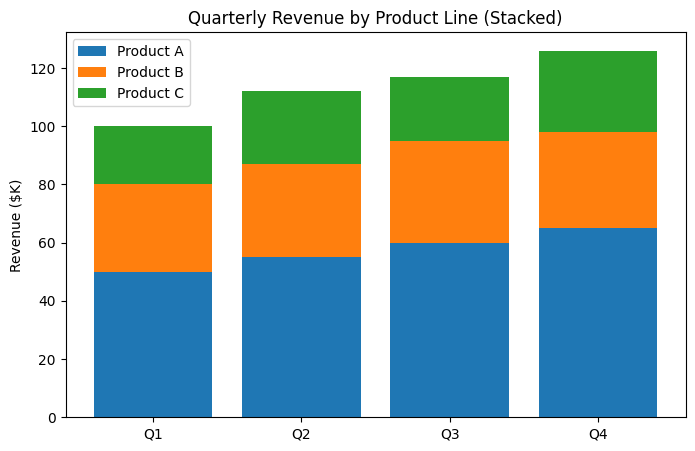

In [ ]:
quarters = ["Q1", "Q2", "Q3", "Q4"]
product_a = np.array([50, 55, 60, 65])
product_b = np.array([30, 32, 35, 33])
product_c = np.array([20, 25, 22, 28])

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(quarters, product_a, label="Product A", color="tab:blue")
ax.bar(quarters, product_b, bottom=product_a, label="Product B", color="tab:orange")
ax.bar(quarters, product_c, bottom=product_a + product_b, label="Product C", color="tab:green")

ax.set_title("Quarterly Revenue by Product Line (Stacked)")
ax.set_ylabel("Revenue ($K)")
ax.legend()
plt.show()


### Line-by-Line Explanation
- First `ax.bar()` call: Product A drawn from `0` up to its own value (default `bottom=0`).
- Second call: `bottom=product_a` — Product B's bars start where Product A's ended, for each quarter (NumPy array addition/alignment handles this per-category automatically).
- Third call: `bottom=product_a + product_b` — Product C stacks on top of A+B combined. **This cumulative-sum-as-bottom pattern generalizes to any number of stacked segments.**

### Internal Working
Exactly like grouped bars, "stacking" is not a distinct Matplotlib primitive — it's the ordinary `bar()` call combined with the `bottom` parameter, computed manually via NumPy array addition. For many segments, `np.cumsum()` along axis 0 of a 2D array is the general-purpose way to compute all `bottom` values at once.

### Percentage (100%) Stacked Variant


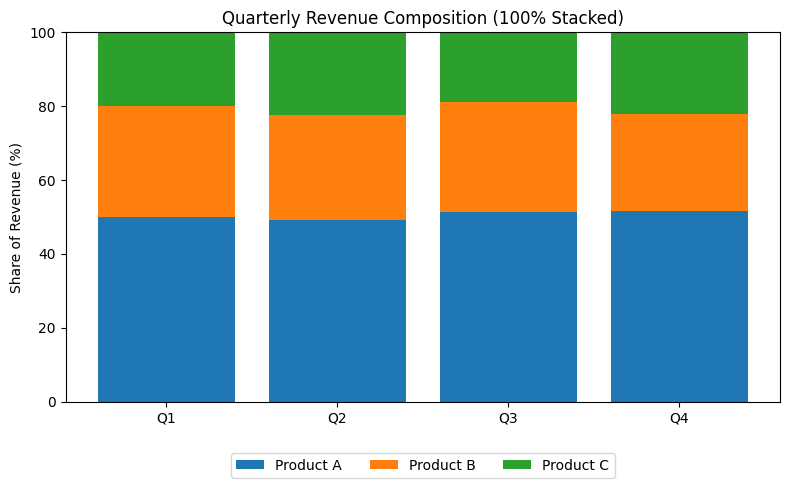

In [ ]:
totals = product_a + product_b + product_c
pct_a, pct_b, pct_c = product_a / totals * 100, product_b / totals * 100, product_c / totals * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(quarters, pct_a, label="Product A", color="tab:blue")
ax.bar(quarters, pct_b, bottom=pct_a, label="Product B", color="tab:orange")
ax.bar(quarters, pct_c, bottom=pct_a + pct_b, label="Product C", color="tab:green")

ax.set_ylim(0, 100)
ax.set_ylabel("Share of Revenue (%)")
ax.set_title("Quarterly Revenue Composition (100% Stacked)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.show()


### Interpretation
The raw-value stacked chart shows total revenue growing across quarters (bar heights increase); the 100%-stacked variant instead isolates *composition* — showing, independent of total growth, whether Product A's *share* of revenue is rising or falling quarter over quarter (useful when total-size changes would otherwise distract from a composition question).

### Common Mistakes
- Forgetting to accumulate `bottom` correctly (e.g., using `bottom=product_b` instead of `bottom=product_a+product_b` for the 3rd segment) — silently overlaps segments instead of stacking them, producing an incorrect-looking but not obviously broken chart.
- Using more than ~4–5 stacked segments — beyond that, middle segments become too thin to label or compare.
- Choosing a stacked bar when the real analytical question is "which sub-group is largest within each category?" — that comparison is much easier read from a grouped bar (Chapter 17), since stacked segments don't share a common baseline.

### Debugging
If segments visually overlap instead of stacking, print the `bottom` array passed to each successive `bar()` call and confirm each is the running cumulative sum of everything already stacked below it.

### Best Practices
- Use stacked bars specifically to show **part-to-whole composition and its trend**, not fine-grained magnitude comparison between sub-groups.
- For a general-purpose N-segment stack, compute `bottoms = np.vstack([np.zeros(len(categories)), np.cumsum(data, axis=0)])[:-1]` rather than manually adding arrays segment by segment.

### Interview Insight
**Q: When would you choose a stacked bar chart over a grouped bar chart?**
A: When the total (sum across sub-groups) and how that total is composed are both meaningful to the reader — e.g., total revenue and its product mix. If instead the reader needs to precisely compare one specific sub-group's magnitude across categories, a grouped bar is easier to read because every bar shares the same zero baseline.

### Mini Exercise
Convert the Chapter 17 grouped-bar model-comparison example into a stacked bar of Precision+Recall+F1 and discuss (in a markdown cell) why this specific stacking is **not** meaningful (hint: these three metrics don't sum to a meaningful "total").

### Quiz (Chapter 18)
1. What Matplotlib parameter enables stacking, and what value must it hold for the 3rd of 3 stacked segments?
2. What analytical question is a 100%-stacked bar chart specifically good for?
3. Why is comparing a middle segment's size across bars harder in a stacked chart than a grouped chart?


---
# CHAPTER 19 — HISTOGRAMS

## 1. Concept
`ax.hist(data, bins=...)` divides the range of a **single numeric variable** into intervals ("bins") and draws a bar for each, whose height represents how many observations fall into that interval — visualizing the variable's **distribution**.

## 2. Why It Matters
A histogram answers questions no single summary statistic can: Is the data symmetric or skewed? Unimodal or multimodal (multiple peaks — often a sign of hidden subgroups)? Are there outliers? A mean/std pair alone cannot reveal any of this (recall Chapter 1's Datasaurus Dozen point).

## 3–4. NumPy / Pandas Connection
`ax.hist(df["age"])` or `ax.hist(np.random.normal(...))` — histograms consume a flat 1D array directly; a Pandas Series works identically to a NumPy array here.

## 5. Industry Use Case
Feature distribution inspection before modeling, target variable distribution (checking for class imbalance in a binned continuous target, or checking skew before deciding on a log-transform), model error/residual distribution.


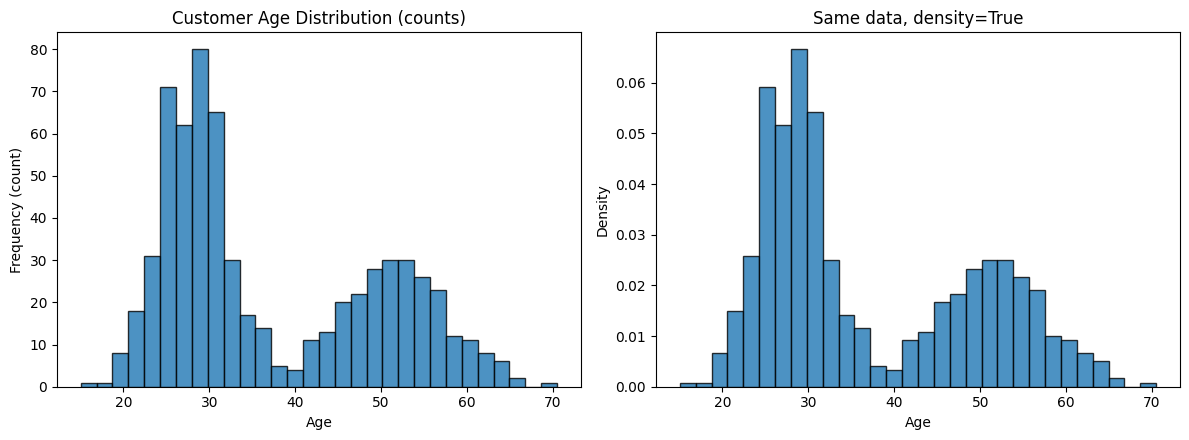

In [ ]:
ages = np.concatenate([
    np.random.normal(28, 4, 400),   # younger cluster
    np.random.normal(52, 6, 250),   # older cluster
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(ages, bins=30, color="tab:blue", edgecolor="black", alpha=0.8)
axes[0].set_title("Customer Age Distribution (counts)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Frequency (count)")

axes[1].hist(ages, bins=30, color="tab:blue", edgecolor="black", alpha=0.8, density=True)
axes[1].set_title("Same data, density=True")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `bins` | Number of intervals, OR an explicit array of bin edges (Chapter 20 goes deep on choosing this) |
| `range` | `(min, max)` — restricts which values are binned, useful to exclude extreme outliers from skewing bin width |
| `density` | If `True`, normalizes so the total area under the bars = 1 (a probability density), instead of raw counts — necessary when comparing two histograms with **different sample sizes** |
| `alpha` | Transparency — essential when overlaying 2+ histograms |
| `histtype` | `'bar'` (default, filled), `'step'` (outline only — better for overlaying multiple distributions), `'stepfilled'` |
| `cumulative` | If `True`, plots a running total instead of per-bin counts (a cumulative distribution view) |
| `orientation` | `'vertical'` (default) or `'horizontal'` |

### What a Histogram Actually Represents
Each bar's height = the **count** (or density) of observations whose value falls within `[bin_edge_i, bin_edge_{i+1})`. The shape immediately reveals:
- **Skewness** — a long tail on one side (e.g., income data is almost always right-skewed).
- **Multi-modality** — two or more distinct peaks, as seen above, often indicating the data is really a mixture of sub-populations (here: two customer age cohorts) that a single mean would obscure entirely.
- **Spread/center** — how wide vs. narrow the bulk of the distribution is.

### Overlaying Two Distributions Correctly


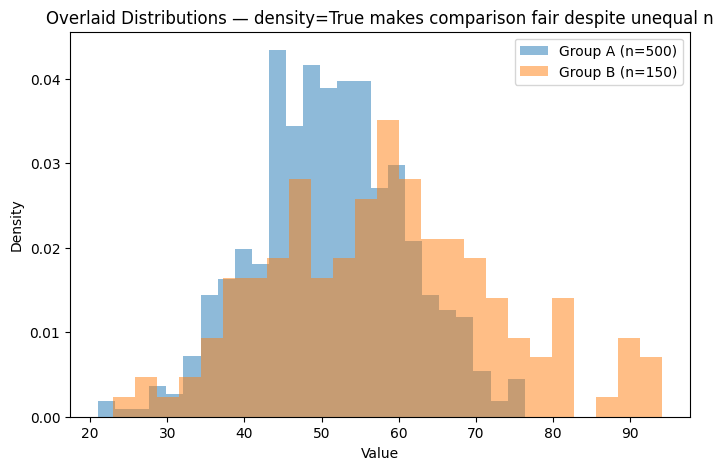

In [ ]:
group_a = np.random.normal(50, 10, 500)
group_b = np.random.normal(58, 14, 150)   # different sample size!

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(group_a, bins=25, alpha=0.5, density=True, label="Group A (n=500)", color="tab:blue")
ax.hist(group_b, bins=25, alpha=0.5, density=True, label="Group B (n=150)", color="tab:orange")
ax.set_title("Overlaid Distributions — density=True makes comparison fair despite unequal n")
ax.set_xlabel("Value")
ax.set_ylabel("Density")
ax.legend()
plt.show()


### Common Mistakes
- Comparing two histograms' raw **counts** when sample sizes differ (e.g., 500 vs 150) — the larger sample will always look "taller," which has nothing to do with the actual distribution shape. Fix: `density=True`.
- Using `histtype='bar'` (filled) for 2+ overlapping distributions instead of `alpha` or `histtype='step'` — filled bars obscure each other.
- Interpreting histogram shape as if it proves normality — a roughly bell-shaped histogram is *suggestive*, not proof; formal tests (Shapiro-Wilk, Q-Q plots) exist for a reason and a histogram alone can't distinguish "approximately normal" from "normal enough for this specific downstream use."

### Debugging
A histogram showing one giant bar and nothing else usually means a single extreme outlier is stretching the auto-computed range across the whole axis — check `data.min()`, `data.max()` and consider `range=` to exclude the outlier from the binning (while still noting it separately) or `ax.set_xlim()` to zoom.

### Best Practices
- Always use `density=True` when comparing groups of different sizes.
- Use `edgecolor="black"` (or similar) on bars — bin boundaries are otherwise hard to see, especially with many bins.
- Note that a **multimodal histogram is itself an insight** — it often means "this variable actually represents two+ different populations," which is directly actionable (e.g., segment before modeling).

### Interview Insight
**Q: You compare a histogram of 500 samples against 150 samples using raw counts, and Group A looks like it "has more" of every value. What's wrong?**
A: Raw counts scale with sample size, so a larger group's histogram will look taller everywhere regardless of the actual shape difference. The fix is `density=True`, which normalizes both histograms to the same total area (1), making shape comparison valid regardless of sample-size mismatch.

### Mini Exercise
Take the bimodal `ages` array from above and compute `ages.mean()` — confirm it lands in the "valley" between the two peaks, a value that describes **neither** actual cluster, illustrating why the histogram is essential here.

### Quiz (Chapter 19)
1. What does a histogram bar's height represent internally?
2. Why is `density=True` necessary when comparing distributions of different sample sizes?
3. What kind of hidden data structure does a multimodal histogram often reveal?
4. Does a bell-shaped histogram prove the data is normally distributed?


---
# CHAPTER 20 — HISTOGRAM BIN SELECTION

## 1. Concept
The number/width of bins fundamentally changes what a histogram appears to show — the same underlying data can look smooth or noisy purely based on this one parameter.

## 2. Why It Matters
Bin count is not a cosmetic choice — it's a bias/variance tradeoff on the visualization itself: too few bins **over-smooths** (hides real structure like the bimodal pattern from Chapter 19); too many bins **under-smooths** (shows noisy, spurious spikes that are just sampling variation, not real structure).


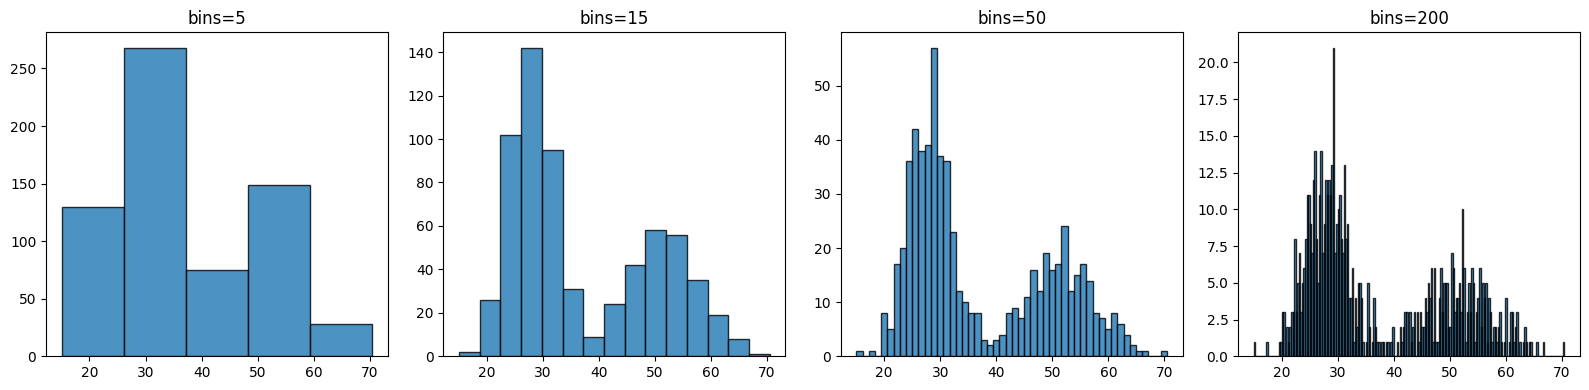

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

bin_counts = [5, 15, 50, 200]
for ax, n_bins in zip(axes, bin_counts):
    ax.hist(ages, bins=n_bins, color="tab:blue", edgecolor="black", alpha=0.8)
    ax.set_title(f"bins={n_bins}")

plt.tight_layout()
plt.show()


### Interpretation
- `bins=5` — **over-smoothed**: the bimodal structure (two customer cohorts) is completely invisible; it looks like one wide, roughly uniform blob.
- `bins=15` — a reasonable middle ground; the two-peak structure starts to emerge.
- `bins=50` — clearly shows both peaks distinctly — this is close to the "right" amount of detail for this dataset.
- `bins=200` — **under-smoothed**: many bins now contain very few points each, introducing jagged, noisy spikes that reflect random sampling variation rather than genuine structure in the population.

### Professional Strategies for Choosing Bins
1. **Start with Matplotlib/NumPy's automatic estimators**: `bins='auto'`, `'fd'` (Freedman-Diaconis, robust to outliers), or `'sturges'` (good for smaller, roughly-normal samples) — pass these strings directly to `bins=`.
2. **Always try 2–3 different bin counts** before settling — bin selection is inherently exploratory, not a single "correct" formula.
3. **Let the analytical question guide it**: if you specifically care about detecting sub-populations, err toward more bins (finer resolution); if you just want a quick "is this roughly normal, skewed, or uniform" read, fewer bins are fine.


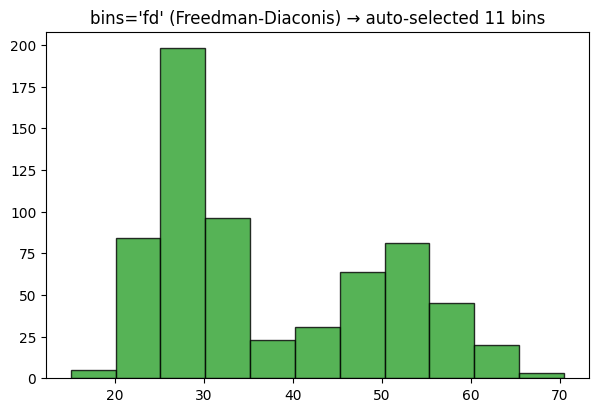

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(ages, bins="fd", color="tab:green", edgecolor="black", alpha=0.8)
n_bins_used = len(np.histogram_bin_edges(ages, bins="fd")) - 1
ax.set_title(f"bins='fd' (Freedman-Diaconis) → auto-selected {n_bins_used} bins")
plt.show()


### Internal Working
`np.histogram_bin_edges(data, bins='fd')` computes the Freedman-Diaconis bin width as `2 * IQR(data) / n^(1/3)` — using the interquartile range (IQR) rather than standard deviation makes it more robust to outliers than some alternative rules (e.g., Scott's rule). Matplotlib's `ax.hist(bins='fd')` calls this same NumPy function internally.

### Common Mistakes
- Accepting Matplotlib's flat default (`bins=10`) without ever checking whether it over- or under-smooths your specific data.
- Assuming there's one single "mathematically correct" bin count — in practice it is a judgment call informed by the analytical goal, checked visually across a few candidate values.

### Best Practices
- Try `bins='auto'` or `'fd'` as a sensible starting point, then adjust up/down by eye.
- When presenting a histogram in a report, briefly note the bin count/strategy used if it materially affects the story (transparency principle, echoed in Chapter 79).

### Interview Insight
**Q: How would you choose the number of bins for a histogram?**
A: Start from an automatic estimator like `'fd'` (Freedman-Diaconis, robust to outliers via IQR) as a reasonable default, then visually compare 2–3 nearby bin counts — checking specifically whether increasing bins reveals genuine structure (like multi-modality) versus just adding noise. There's no single universally-correct bin count; it's guided by the specific analytical question.

### Mini Exercise
Compute and compare the bin count chosen by `bins='auto'`, `'fd'`, and `'sturges'` on the `ages` array using `len(np.histogram_bin_edges(ages, bins=strategy)) - 1` for each.

### Quiz (Chapter 20)
1. What happens to real structure in the data when too few bins are used?
2. What happens when too many bins are used?
3. What statistic does the Freedman-Diaconis rule use that makes it robust to outliers?


---
# CHAPTER 21 — KDE CONCEPTUAL COMPARISON

## 1. Concept
A **Kernel Density Estimate (KDE)** is a smoothed, continuous curve estimating the underlying probability density a histogram's discrete bins only approximate. Instead of counting how many points fall in fixed-width bins, KDE places a small smooth "kernel" (usually Gaussian) over every single data point and sums them all up into one continuous curve.

## Histogram vs KDE vs Density Estimation — Conceptual Comparison
| | Histogram | KDE |
|---|---|---|
| Output | Discrete bars | Smooth continuous curve |
| Sensitive to | Bin count/edges (Chapter 20) | Bandwidth (smoothing parameter) — same bias/variance tradeoff, different knob |
| Binary/count nature | Shows raw counts naturally | Always shows a smoothed density, never raw counts |
| Best for | Quick, honest look at raw data, especially with a moderate sample | Comparing distribution *shapes* smoothly, presentation-quality curves |

**Important scope note**: pure Matplotlib does not include a built-in KDE function — computing one requires `scipy.stats.gaussian_kde` or Pandas' `.plot.kde()` (which itself calls `scipy` under the hood). This course's focus is Matplotlib as the *rendering* layer; the code below shows how KDE output — once computed — is simply plotted with `ax.plot()`, no different from any other line.


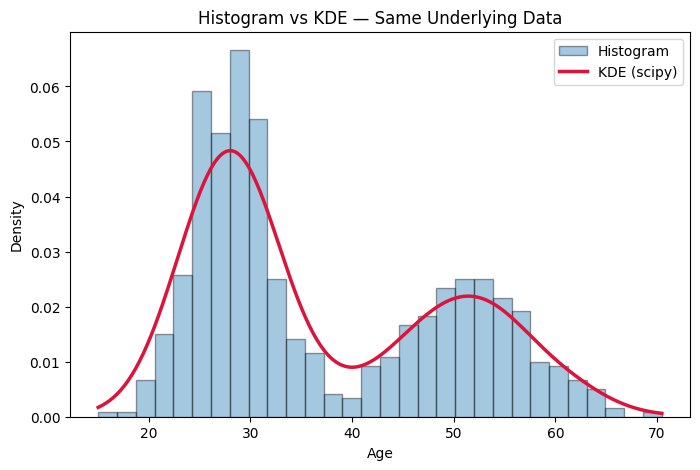

In [ ]:
from scipy import stats

fig, ax = plt.subplots(figsize=(8, 5))

# Histogram (density=True so it's on the same y-scale as the KDE curve)
ax.hist(ages, bins=30, density=True, alpha=0.4, color="tab:blue", label="Histogram", edgecolor="black")

# KDE computed via scipy, then rendered with a plain ax.plot() — nothing KDE-specific in Matplotlib itself
kde = stats.gaussian_kde(ages)
x_grid = np.linspace(ages.min(), ages.max(), 300)
ax.plot(x_grid, kde(x_grid), color="crimson", linewidth=2.5, label="KDE (scipy)")

ax.set_title("Histogram vs KDE — Same Underlying Data")
ax.set_xlabel("Age")
ax.set_ylabel("Density")
ax.legend()
plt.show()


### Interpretation
The KDE curve confirms the same bimodal structure the well-chosen histogram (Chapter 20) revealed, but presents it as a single smooth, publication-ready curve — useful specifically when the deliverable is a stakeholder-facing report where bar "steppiness" would look unpolished, or when overlaying 3+ groups (overlapping histogram bars get visually messy fast, overlapping KDE lines stay clean).

### Common Mistakes
- Treating a smooth KDE curve as if it reveals more "truth" than the histogram — it's a smoothed **estimate**, and its own smoothing parameter (bandwidth) can hide or fabricate structure exactly like bin count can for histograms.
- Forgetting `density=True` on the histogram when overlaying it with a KDE (which is always density-scaled) — otherwise the two won't be on the same y-scale and the overlay will look wrong.

### Best Practices
- Use histogram + KDE overlay together, not KDE alone, when precision about raw counts still matters (KDE alone can visually mislead about how much data exists in sparse regions).
- Prefer KDE-only, no histogram, when overlaying 3+ groups' distributions on one Axes for a clean presentation chart.

### Interview Insight
**Q: What's the practical tradeoff between a histogram and a KDE for a stakeholder-facing report?**
A: A histogram is more "honest" about the raw, discrete counts and doesn't require choosing an extra smoothing parameter (bandwidth), but can look jagged/unpolished and is harder to overlay across many groups; a KDE produces a clean, smooth, easily-overlaid curve but is itself a modeled estimate whose bandwidth choice can just as easily over- or under-smooth real structure, similar to bin-count choice in a histogram.

### Mini Exercise
Recompute the KDE using `stats.gaussian_kde(ages, bw_method=0.1)` (a much smaller/finer bandwidth) and compare how it changes the smoothness of the curve versus the default bandwidth used above.

### Quiz (Chapter 21)
1. What does a KDE place over every data point to build its curve?
2. What is the KDE analogue of a histogram's "bin count" tuning knob?
3. Does pure Matplotlib include a built-in KDE computation function?


---
# CHAPTER 22 — BOX PLOTS

## 1. Concept
`ax.boxplot(data)` summarizes a distribution using five numbers: minimum (within a computed range), Q1 (25th percentile), median (Q2/50th), Q3 (75th percentile), and maximum (within range) — plus explicitly flagged outliers beyond that range.

```
        Q1 - 1.5*IQR         Q1      Median      Q3        Q3 + 1.5*IQR
             |------[=========|==========|=========]------|
           whisker         box (IQR)              whisker
                                                              o  o   ← outliers beyond whiskers
```
Where **IQR = Q3 − Q1**.

## 2. Why It Matters
Box plots are the most compact way to compare a distribution's **center, spread, skew, and outliers across many groups side by side** — something a histogram can only do one or two groups at a time before becoming visually cluttered.

## 3–4. NumPy / Pandas Connection
`ax.boxplot(df.groupby("department")["salary"].apply(list))` or simply passing a list of Pandas Series/arrays, one per group — box plots consume a **list of arrays**, one array per box.

## 5. Industry Use Case
Comparing salary/revenue/error distributions across many departments, models, or segments simultaneously; spotting which group has unusually wide spread or many outliers.


/tmp/ipykernel_788/2320080622.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


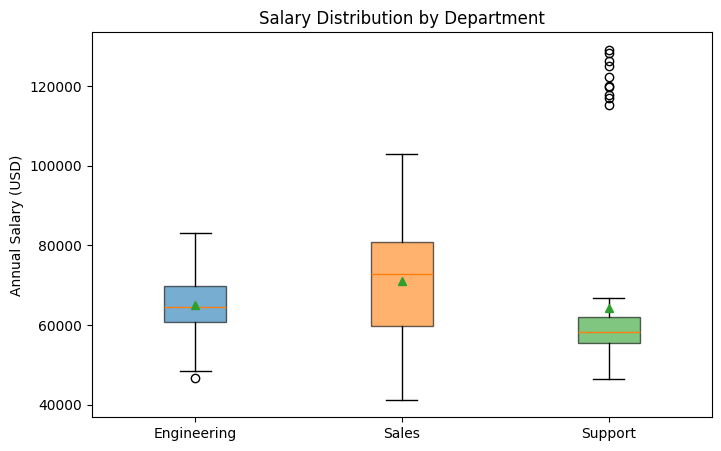

In [ ]:
np.random.seed(7)
dept_a = np.random.normal(65000, 8000, 100)
dept_b = np.random.normal(72000, 15000, 100)
dept_c = np.concatenate([np.random.normal(58000, 5000, 90), np.random.normal(120000, 5000, 10)])  # has outliers

fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(
    [dept_a, dept_b, dept_c],
    labels=["Engineering", "Sales", "Support"],
    patch_artist=True,      # allows filling boxes with color
    showmeans=True,
)

for patch, color in zip(bp["boxes"], ["tab:blue", "tab:orange", "tab:green"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax.set_title("Salary Distribution by Department")
ax.set_ylabel("Annual Salary (USD)")
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `labels` | Category names, one per array passed |
| `patch_artist` | If `True`, boxes become fillable `Patch` objects (needed to set `facecolor`) |
| `showmeans` | Overlays a marker for the mean in addition to the median line |
| `notch` | If `True`, draws a notched box indicating a confidence interval around the median (useful for a rough visual significance check between groups) |
| `whis` | Multiplier for whisker length (default `1.5 × IQR`); can be set to a percentile pair like `(5, 95)` instead |

### Return Value / Internal Working
`ax.boxplot()` returns a dictionary of Artist lists: `{'boxes': [...], 'medians': [...], 'whiskers': [...], 'caps': [...], 'fliers': [...], 'means': [...]}` — this is why per-box coloring above required iterating `bp["boxes"]` directly rather than a single simple call.

### Interpretation
- **Engineering**: relatively tight, symmetric spread around ~$65K.
- **Sales**: wider spread (taller box + longer whiskers) — more variable compensation, possibly reflecting commission structures.
- **Support**: a compact box near $58K but with distinct outlier points (`fliers`) far above the whiskers — these are the ~10 unusually high earners injected into the synthetic data, and a box plot flags them explicitly as individual points rather than just widening the whisker to include them.

### Common Mistakes
- Treating every flagged "outlier" (flier) as automatically an error/anomaly to delete — some are genuine, valid extreme observations (e.g., a senior director's salary correctly included in a "Support" department dataset) and deleting them without investigation is a serious analytical mistake (this connects directly to Chapter 68's "Outlier vs valid rare observation" distinction).
- Comparing box plots across groups with very different sample sizes without noting `n` for each — box plots don't visually communicate sample size at all by default.
- Using a box plot when the audience needs to see the actual **shape** of the distribution (bimodality, for instance) — a box plot's five-number summary can look identical for a unimodal and a bimodal distribution with the same median/quartiles; a violin plot (Chapter 23) or histogram is needed to reveal that.

### Debugging
If `ax.boxplot()` raises a `TypeError`, check that you passed a **list of arrays** (or a single 2D array), not a single flat 1D array meant to represent multiple groups — a common mixup when refactoring from a single-histogram call.

### Best Practices
- Always pair a box plot with the sample size per group (in the label or a caption) when `n` varies meaningfully.
- Investigate fliers before deciding whether to treat them as errors or genuine rare events.
- Use `notch=True` for a quick, informal visual read on whether two groups' medians likely differ meaningfully — not a substitute for a proper statistical test, but a fast first look.

### Interview Insight
**Q: A box plot flags several points above the upper whisker as outliers. Should you remove them?**
A: Not automatically. "Outlier" here just means "beyond 1.5×IQR from the box" — a purely statistical/positional definition, not a judgment about validity. You need to investigate each flagged point in context: it could be a data-entry error (fix/remove) or a genuine rare event that's analytically important to keep (e.g., a legitimate large transaction).

### Mini Exercise
Recreate the box plot with `notch=True` and observe the notch shape around each median — note (in a markdown cell) whether the notches for any two departments overlap.

### Quiz (Chapter 22)
1. What five numbers does a standard box plot summarize?
2. What does `patch_artist=True` enable, and why was it needed above?
3. Why can two very differently-shaped distributions produce visually identical box plots?
4. Should a flagged "outlier" point always be removed from the data?


---
# CHAPTER 23 — VIOLIN PLOTS

## 1. Concept
`ax.violinplot(data)` combines a box plot's group-comparison layout with a KDE's full distribution shape — each "violin" is a mirrored, smoothed density curve, with the width at any given y-value showing how common that value is.

## Histogram vs Box Plot vs Violin Plot
| Chart | Shows shape? | Compares many groups easily? | Shows exact quartiles clearly? |
|---|---|---|---|
| Histogram | Yes (fully) | No (1–2 groups max before clutter) | No |
| Box Plot | No (5-number summary only) | Yes | Yes (explicit lines) |
| Violin Plot | Yes (via embedded KDE shape) | Yes | Only approximately (unless overlaid with box plot internals) |


/tmp/ipykernel_788/3376805145.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data_groups, labels=labels)


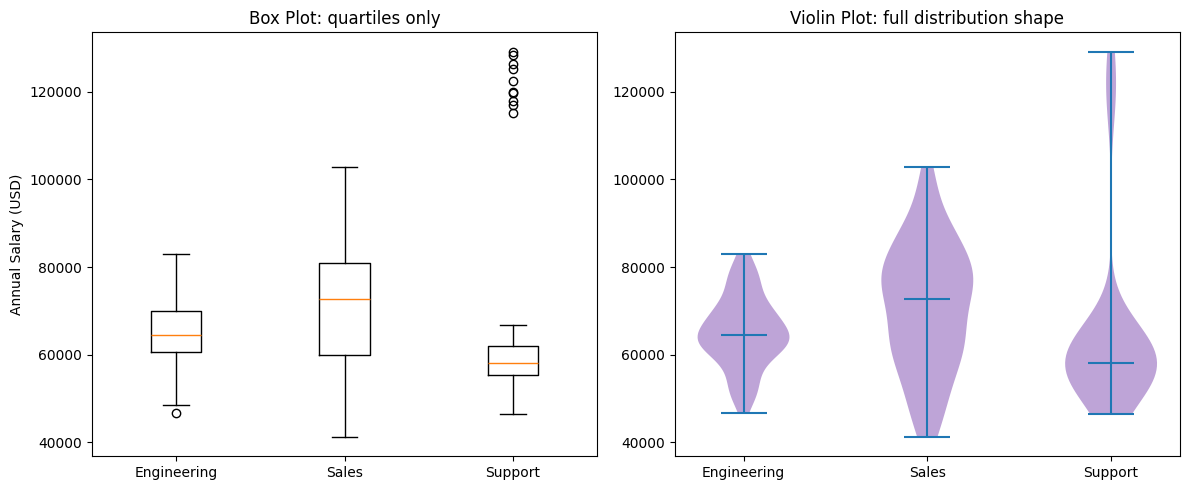

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

data_groups = [dept_a, dept_b, dept_c]
labels = ["Engineering", "Sales", "Support"]

# Box plot for direct comparison
axes[0].boxplot(data_groups, labels=labels)
axes[0].set_title("Box Plot: quartiles only")
axes[0].set_ylabel("Annual Salary (USD)")

# Violin plot reveals shape (note: Support's bimodal-like tail from injected outliers)
parts = axes[1].violinplot(data_groups, showmedians=True)
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(labels)
axes[1].set_title("Violin Plot: full distribution shape")

for pc in parts["bodies"]:
    pc.set_facecolor("tab:purple")
    pc.set_alpha(0.6)

plt.tight_layout()
plt.show()


### Parameter Explanation
- `showmedians=True` — draws a short horizontal line at each group's median (violin plots don't show this by default, unlike box plots).
- `showmeans` / `showextrema` — similarly toggle additional summary markers.
- Return value `parts` is a dict including `'bodies'` (the filled violin shapes, styled above), `'cmedians'`, `'cmeans'`, etc. — styled the same way as box plot's returned dict in Chapter 22.

### Interpretation
The Support department's violin visibly widens again near the top (reflecting the injected high-salary outliers as a genuine secondary density bump, not just a few isolated flier dots) — information the box plot compressed into a handful of individual point markers. This is the core advantage of a violin plot: it shows *how much* density exists in the tail, not just *that* some points exist there.

### Common Mistakes
- Using violin plots with very small sample sizes (n < ~20 per group) — the underlying KDE becomes unreliable and can visually fabricate smooth structure that doesn't really exist in so few points.
- Assuming a violin's "width" at a point directly equals a count — it's a smoothed *density* estimate (same caveats as KDE in Chapter 21), not raw counts, so a violin's shape should be read qualitatively (bulges = more common regions), not read for precise numbers.

### Best Practices
- Use violin plots when both the summary comparison (box-plot-like) **and** the full distribution shape matter to the audience — e.g., detecting sub-populations across multiple groups at once.
- For a technical audience already comfortable with box plots, consider overlaying a thin box plot on top of the violin for the best of both (exact quartile lines + shape).

### Interview Insight
**Q: When would you choose a violin plot over a box plot?**
A: When the distribution's *shape* — especially multi-modality or heavy skew — is analytically important and you still need to compare that across several groups simultaneously. A box plot's 5-number summary can hide multi-modality entirely; a violin plot's embedded density estimate reveals it.

### Mini Exercise
Reduce `dept_c`'s sample size to `n=8` (regenerate with fewer points) and observe how much noisier/less trustworthy the resulting violin shape looks compared to the box plot for the same tiny sample.

### Quiz (Chapter 23)
1. What underlying technique from Chapter 21 powers a violin plot's shape?
2. What does `showmedians=True` add that isn't there by default?
3. Why are violin plots unreliable for very small sample sizes?


---
# CHAPTER 24 — PIE CHARTS

## 1. Concept
`ax.pie(values, labels=...)` divides a circle into wedges proportional to each category's share of a whole.

## Why Pie Charts Are Often Discouraged
Human perception is **much worse at comparing angles/areas** than at comparing the length/position of bars along a common baseline (a well-established finding in visualization research, going back to Cleveland & McGill's classic perceptual studies). Two wedges of similar size (e.g., 23% vs 27%) are genuinely hard to rank correctly by eye — the equivalent two bars are trivial to rank.

## When Pies Can Be (Cautiously) Acceptable
- Very few categories (2–3) with clearly different sizes (e.g., 70% vs 30%).
- The explicit communication goal is "this is a share of a single whole" as the primary message, not precise ranking.
- Never for more than ~5 categories, and never with a legend forcing the reader to cross-reference many small colored slivers back to a separate list.


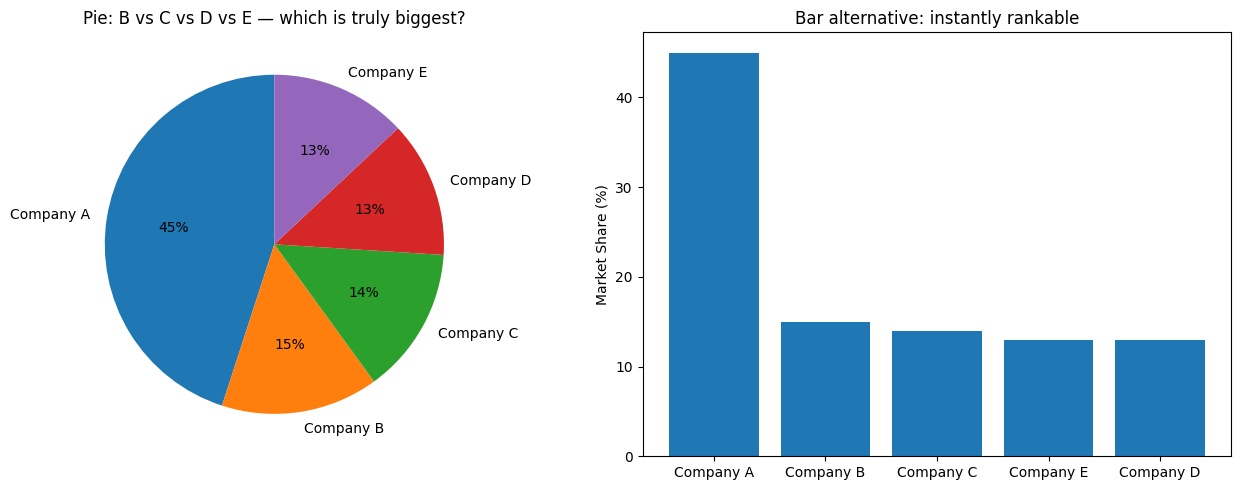

In [ ]:
market_share = [45, 15, 14, 13, 13]
companies = ["Company A", "Company B", "Company C", "Company D", "Company E"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie chart — hard to compare B, C, D, E precisely
axes[0].pie(market_share, labels=companies, autopct="%1.0f%%", startangle=90)
axes[0].set_title("Pie: B vs C vs D vs E — which is truly biggest?")

# Bar chart alternative — trivial to rank precisely
order = np.argsort(market_share)[::-1]
axes[1].bar(np.array(companies)[order], np.array(market_share)[order], color="tab:blue")
axes[1].set_title("Bar alternative: instantly rankable")
axes[1].set_ylabel("Market Share (%)")

plt.tight_layout()
plt.show()


### Parameter Explanation
- `autopct="%1.0f%%"` — a format string automatically computing and displaying each wedge's percentage.
- `startangle=90` — rotates the first wedge to start at 12 o'clock instead of 3 o'clock, a common readability convention.
- `explode=(0, 0, 0, 0, 0.1)` — optionally "pulls out" one wedge for emphasis (not used above, but common for highlighting one category).

### Interpretation
In the pie chart, telling apart Company B (15%), C (14%), D (13%), and E (13%) by wedge angle alone is genuinely difficult — you likely needed the printed `autopct` percentages to be sure, which somewhat defeats the purpose of a purely visual comparison. The bar chart makes the same ranking immediate and needs no printed numbers at all to be trusted.

### Common Mistakes
- Using a pie chart for 6+ categories — becomes an unreadable wheel of thin slivers.
- Using 3D "exploded" pie charts — perspective distortion makes the *already-hard* angle comparison even less accurate (a specific case of the "misleading visualization" pattern in Chapter 79).
- Using multiple pie charts side-by-side to compare the same categories across time/groups — nearly impossible to track a single category's change across separate wheels; a stacked or grouped bar (Chapters 17–18) does this far better.

### Best Practices
- Default to a bar chart for category comparison; reach for a pie chart only for a very small number of categories where the "part of a whole" framing is the specific, deliberate message (e.g., "just over half of respondents chose X").
- If you do use a pie chart, always include `autopct` percentages — don't force the reader to guess.

### Interview Insight
**Q: A colleague asks you to build a pie chart with 8 categories. What do you recommend instead, and why?**
A: A sorted bar chart (or horizontal bar chart if labels are long). Angular/area comparisons across many similarly-sized wedges are one of the weakest human perceptual judgments, per Cleveland & McGill's rankings of visual encodings — length/position along a common baseline (what a bar chart provides) is one of the strongest, making rankings and precise comparisons far easier and less error-prone for the reader.

### Mini Exercise
Reduce the pie chart to just 2 categories with a 70/30 split and observe how much easier that specific comparison is — illustrating that pie charts aren't *always* wrong, just poorly suited to many/similar-sized categories.

### Quiz (Chapter 24)
1. What perceptual weakness makes pie charts hard to read accurately for many categories?
2. Under what specific condition can a pie chart be an acceptable choice?
3. What alternative chart is almost always better for ranking categories precisely?


---
# CHAPTER 25 — AREA PLOTS AND FILL BETWEEN

## 1. Concept
`ax.fill_between(x, y1, y2)` shades the region between two curves (or between one curve and a baseline, e.g., `y2=0`) — used for area plots, confidence intervals, and forecast/uncertainty bands.

## 2. Why It Matters
This is the standard technique for visualizing **uncertainty** — a model's confidence interval, an experiment's variance across runs, or a forecast range — which is exactly the kind of information a single line alone cannot convey. Reporting a point prediction without its uncertainty band can overstate confidence in a business or ML context.

## 3–4. NumPy / Pandas Connection
`y1`/`y2` are typically computed as `mean ± std` or a percentile band from repeated experiment runs, model bootstrap samples, or (in time series) rolling statistics — all standard NumPy/Pandas aggregations feeding directly into `fill_between`.

## 5. Industry Use Case
- Confidence/prediction intervals around a forecast.
- "Min–max across N random seeds" bands for ML experiment reproducibility reporting.
- Cumulative quantity visualization (classic stacked area plots for cumulative revenue, etc.).


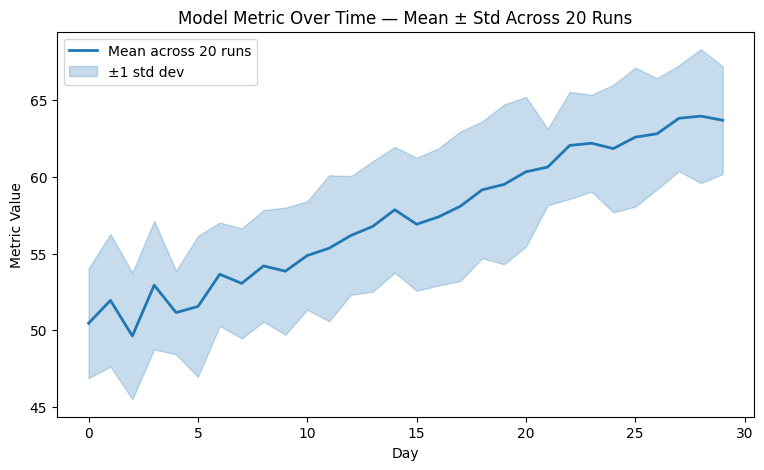

In [ ]:
days = np.arange(30)
np.random.seed(3)
# Simulate 20 independent runs of a noisy metric (e.g., 20 random seeds of a model's daily performance)
runs = np.array([50 + 0.5 * days + np.random.normal(0, 4, size=30) for _ in range(20)])

mean_metric = runs.mean(axis=0)
std_metric = runs.std(axis=0)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(days, mean_metric, color="tab:blue", linewidth=2, label="Mean across 20 runs")
ax.fill_between(
    days,
    mean_metric - std_metric,
    mean_metric + std_metric,
    color="tab:blue",
    alpha=0.25,
    label="±1 std dev",
)

ax.set_title("Model Metric Over Time — Mean ± Std Across 20 Runs")
ax.set_xlabel("Day")
ax.set_ylabel("Metric Value")
ax.legend()
plt.show()


### Line-by-Line Explanation
- `runs = np.array([... for _ in range(20)])` — a `(20, 30)` NumPy array: 20 simulated experiment runs × 30 days each.
- `runs.mean(axis=0)` / `runs.std(axis=0)` — aggregate **across runs** (axis 0), producing one mean/std value **per day** (30 values each) — a classic NumPy axis-aggregation pattern directly feeding a visualization.
- `ax.fill_between(days, mean - std, mean + std, alpha=0.25)` — shades the band between the lower and upper bound curves; low `alpha` is essential so the shaded band doesn't visually dominate the mean line it's supporting.

### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `x` | Shared x-values for both curves |
| `y1`, `y2` | Lower and upper boundary curves (or `y2=0`/scalar for a simple area-under-curve fill) |
| `where` | Optional boolean array — only fills where `True` (e.g., only shade regions where a threshold is exceeded) |
| `interpolate` | If `True`, correctly fills boundary crossings when using `where=` on noisy/crossing curves |
| `alpha` | Transparency — should almost always be well below 1 for a band overlay |

### Internal Working
`fill_between` constructs a `PolyCollection` Artist — a single filled polygon connecting `(x, y1)` forward and `(x, y2)` in reverse — rather than many small rectangles, making it efficient even for long time series.

### Interpretation
The shaded band's width communicates the metric's **run-to-run variability** at each point in time — notice whether the band widens or narrows over the 30 days; a widening band would indicate increasing uncertainty/instability over time, an insight completely invisible from the mean line alone.

### Common Mistakes
- Setting `alpha=1` (or omitting it) on a confidence band — fully opaque bands obscure the mean line and any data points that would otherwise be visible underneath.
- Forgetting to also plot the central line (`mean_metric`) — a band with no center line makes it hard to see the "best estimate," only the range.
- Using `fill_between` with mismatched `y1`/`y2` array lengths versus `x` — the #1 error source, identical in nature to the line-plot length mismatch from Chapter 4.

### Debugging
`ValueError` from `fill_between` almost always means `x`, `y1`, `y2` don't share the same length — print `.shape` on all three before the call.

### Best Practices
- Always pair a `fill_between` band with a clear center line (mean/median/point-forecast).
- Use `alpha` in the 0.15–0.35 range for bands so they read as "uncertainty" rather than competing visually with the main line.
- Label the band precisely in the legend (e.g., "±1 std dev" vs "95% CI" — these are different and readers shouldn't have to guess which).

### Interview Insight
**Q: How would you visualize a forecast along with its uncertainty?**
A: Plot the point forecast as a solid line (or dashed, per the historical/forecast convention from Chapter 9) and use `ax.fill_between()` with a low `alpha` to shade the confidence interval (e.g., a 95% interval's lower and upper bounds) around it — always labeling exactly what the band represents (a specific confidence level, or ±1 std dev, etc.) so it isn't ambiguous.

### Mini Exercise
Add a second, wider band representing ±2 standard deviations (using a lower `alpha`, e.g., `0.1`) layered behind the existing ±1 std dev band, so the chart shows two nested uncertainty levels.

### Coding Challenge
Write a function `plot_mean_with_band(x, runs_2d_array, ax=None, label="Mean")` that computes mean and std across `axis=0` of a 2D array and renders exactly the mean-line + shaded-band pattern above, returning `(fig, ax)`.


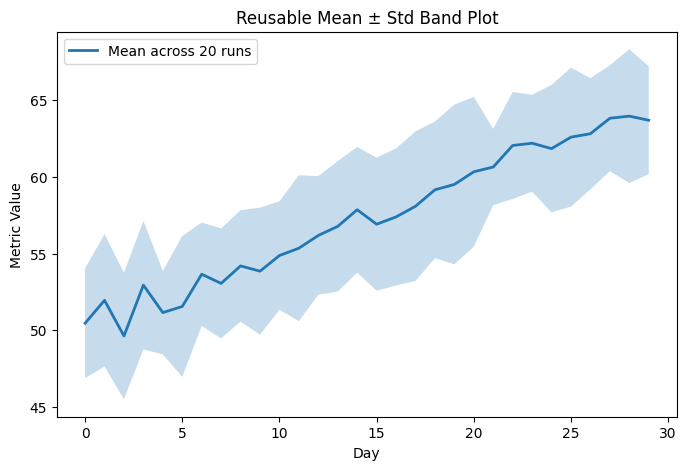

In [ ]:
def plot_mean_with_band(x, runs_2d_array, ax=None, label="Mean"):
    mean_vals = runs_2d_array.mean(axis=0)
    std_vals = runs_2d_array.std(axis=0)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    else:
        fig = ax.get_figure()

    ax.plot(x, mean_vals, linewidth=2, label=label)
    ax.fill_between(x, mean_vals - std_vals, mean_vals + std_vals, alpha=0.25)
    return fig, ax

fig, ax = plot_mean_with_band(days, runs, label="Mean across 20 runs")
ax.set_title("Reusable Mean ± Std Band Plot")
ax.set_xlabel("Day")
ax.set_ylabel("Metric Value")
ax.legend()
plt.show()


### Quiz (Chapter 25)
1. What Artist type does `fill_between` create internally?
2. Why should a confidence band almost always use `alpha < 1`?
3. What's the most common source of a `ValueError` from `fill_between`?
4. Name two industry use cases for `fill_between` beyond simple time-series confidence bands.

### Chapter 25 Summary
- `fill_between` shades uncertainty/composition regions between two curves; always pair it with a labeled center line and low alpha.
- The mean/std-across-axis-0 pattern is a standard NumPy→Matplotlib pipeline for experiment-reproducibility reporting.

---

## END OF NOTEBOOK 3 — What You Should Now Be Able To Do
- Build horizontal bars correctly (including the ascending-sort gotcha) for long-label rankings like feature importance.
- Construct grouped bars from scratch using the general offset formula, and stacked bars using cumulative `bottom` values (raw and 100%-normalized).
- Choose, build, and correctly interpret histograms, understand the bin-count bias/variance tradeoff, and know where KDE fits conceptually.
- Read and build box plots and violin plots, and articulate exactly when each is preferable.
- Explain precisely why pie charts are usually a weaker choice than bar charts, and when they're still acceptable.
- Build and interpret `fill_between` uncertainty bands, and reuse the pattern as a function.

 
